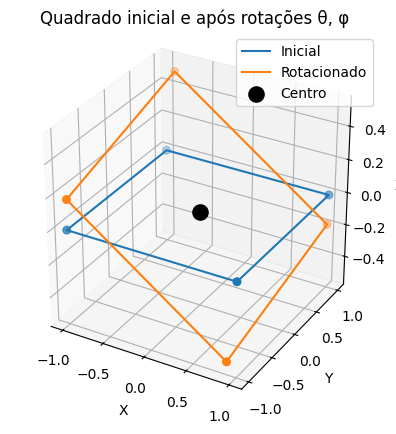

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def rotated_square(a: float, b: float, theta: float, phi: float):
    """
    Return initial and rotated vertices of a square in 3-D.

    Parameters
    ----------
    a, b  : half-widths along +X and +Y (initial square is 2a × 2b)
    theta : rotation about the X-axis (rad)
    phi   : rotation about the Y-axis (rad)

    Returns
    -------
    tuple[np.ndarray, np.ndarray]
        (initial_vertices, rotated_vertices), each shape (4, 3).
    """
    vertices = np.array([
        [-a, -b, 0.0],
        [ a, -b, 0.0],
        [ a,  b, 0.0],
        [-a,  b, 0.0]
    ])

    Rx = np.array([
        [1.0,            0.0,             0.0],
        [0.0,  np.cos(theta), -np.sin(theta)],
        [0.0,  np.sin(theta),  np.cos(theta)]
    ])

    Ry = np.array([
        [ np.cos(phi), 0.0, np.sin(phi)],
        [        0.0, 1.0,        0.0 ],
        [-np.sin(phi), 0.0, np.cos(phi)]
    ])

    R = Ry @ Rx            # X then Y
    rotated = vertices @ R.T
    return vertices, rotated

# Example parameters
a, b = 1.0, 1.0
theta = np.radians(10)   # 30° about X
phi   = np.radians(20)   # 20° about Y

v_init, v_rot = rotated_square(a, b, theta, phi)

# Close the squares by repeating the first vertex
v_init_closed = np.vstack([v_init, v_init[0]])
v_rot_closed  = np.vstack([v_rot,  v_rot[0]])

# Single 3-D plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot initial and rotated squares
ax.plot(v_init_closed[:,0], v_init_closed[:,1], v_init_closed[:,2],
        label="Inicial")
ax.plot(v_rot_closed[:,0], v_rot_closed[:,1], v_rot_closed[:,2],
        label="Rotacionado")

# Scatter vertices
ax.scatter(v_init[:,0], v_init[:,1], v_init[:,2], s=30)
ax.scatter(v_rot[:,0], v_rot[:,1], v_rot[:,2], s=30)

# Scatter center (always the origin)
ax.scatter(0, 0, 0, s=120, c='black', marker='o', label="Centro")

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.set_box_aspect([1,1,1])
ax.set_title("Quadrado inicial e após rotações θ, φ")
ax.legend()

plt.show()
